# Fig 7 — Interventionally dialing the prior loading factor $\lambda$

Given the cached prediction states $\boldsymbol y$ of Llama 3.2-3B on the 200 WikiText
passages at late-context position 299 (where the natural $\lambda_0$ is lowest), we
patch the final pre-unembedding state

$$\boldsymbol y(\lambda^*) = \boldsymbol y + (\lambda^* - \lambda_0)\,\boldsymbol d_{\mathrm{prior}},
\qquad \boldsymbol d_{\mathrm{prior}} \equiv \beta^*\,\hat{\boldsymbol d}_{\mathrm{prior}},$$

keeping the context component fixed while sweeping $\lambda^* \in [-0.5, 1.5]$, and
measure $\mathrm{KL}(p_{\lambda^*}\,\|\,p_{\mathrm{unigram}})$ and
$\mathrm{KL}(p_{\lambda^*}\,\|\,\hat p_{\mathrm{prior}})$ (mean $\pm\,2$ SE across passages).
The tempered-Bayes prediction is a convex curve diving to near-zero KL at the
calibrated value $\lambda^*\approx 1$ and turning back up past it. The red control
applies the same-magnitude perturbation along random directions.

`vocab_coverage = 0.6` controls **both** how $\hat{\boldsymbol d}_{\mathrm{prior}}$ / $\beta^*$
are fitted and the token support on which $p_{\mathrm{unigram}}$ is defined. Since the
cached $\boldsymbol y$ is the lm_head input (post final norm), the intervention needs no
forward pass — only products with the cached $W_{\mathrm{out}}$.

In [1]:
import os
os.environ.pop("HF_TOKEN", None)
os.environ.pop("HUGGING_FACE_HUB_TOKEN", None)

In [2]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from transformers import AutoTokenizer

# Self-contained layout: direction_of_ignorance/{scripts, data, notebook_plotters}
cwd = Path.cwd().resolve()
ROOT = cwd.parent if cwd.name == "notebook_plotters" else cwd
SCRIPTS_DIR = ROOT / "scripts"
DATA_DIR = ROOT / "data"
if str(SCRIPTS_DIR) not in sys.path:
    sys.path.insert(0, str(SCRIPTS_DIR))

import utils
import pile_token_stats

In [3]:
#######################################################
##### Configuration
#######################################################
model_name = "meta-llama/Llama-3.2-3B"

# Must match the fig2 cache that stores raw prediction states.
script_num = 200   # WikiText passages
tok_num = 300      # tokens per passage
position = 299     # late-context position where natural lambda_0 is lowest

# Coverage controls BOTH the d_prior / beta_star fit and the token support on
# which p_unigram is defined.
vocab_coverage = 0.6

# Intervention sweep.
lambda_grid = np.linspace(-0.5, 1.5, 41)
n_random_dirs = 8       # random-direction control, averaged per passage
random_seed = 0

fig2_cache_dir = DATA_DIR / "fig2_cache"
_tag = model_name.replace("/", "__")
hidden_path = fig2_cache_dir / f"panelA_y_{_tag}_N{script_num}_T{tok_num}_coherent.npy"
unembedding_path = fig2_cache_dir / f"panelA_Wout_{_tag}_float32.npy"
for _path in (hidden_path, unembedding_path):
    if not _path.exists():
        raise FileNotFoundError(
            f"Missing {_path.name}; run the fig2 compute driver first to cache it."
        )
print(f"raw y cache      : {hidden_path.name}")
print(f"W_out cache      : {unembedding_path.name}")

raw y cache      : panelA_y_meta-llama__Llama-3.2-3B_N200_T300_coherent.npy
W_out cache      : panelA_Wout_meta-llama__Llama-3.2-3B_float32.npy


In [4]:
# Fit d_prior / beta_star from cached W_out at the requested coverage, and
# define the two reference distributions on the coverage token support:
#   p_unigram : empirical Pile unigram probabilities (top tokens up to coverage)
#   p_prior   : softmax(beta_star * W @ d_hat), the model's own fitted prior
tokenizer = AutoTokenizer.from_pretrained(model_name)
w_out = np.load(unembedding_path, mmap_mode="r")
vocab_size = w_out.shape[0]

pile_source = "monology/pile-uncopyrighted"
tokenizer_tag = pile_token_stats.tokenizer_cache_tag(tokenizer, vocab_size=vocab_size)
cache_name = f"{tokenizer_tag}__{pile_source.replace('/', '__')}__token_probs.npz"
p_zipf = pile_token_stats.empirical_token_prob(
    tokenizer,
    vocab_size=vocab_size,
    coverage=vocab_coverage,
    dataset_name=pile_source,
    split="train",
    text_column="text",
    cache_path=DATA_DIR / "token_stats" / cache_name,
    report_every=1_000,
)

fit = utils.frequency_dipole(
    w_out,
    p_zipf,
    method="optimal_prior",
    exclude_zeros=True,
)
d_hat = utils.unit_vector(fit["d_star"])
beta_star = float(fit["beta_star"])
support = np.asarray(fit["mask"], dtype=bool)  # tokens retained at this coverage
print(
    f"optimal-prior fit: {fit['n_tokens']:,}/{vocab_size:,} tokens, "
    f"beta_star={beta_star:.4g}, R2={fit['r2']:.4f}, nKL={fit['nkl']:.4f}"
)

# Restrict everything to the coverage support. Model probabilities are taken
# as softmax over the support logits (i.e. conditioned on the support), which
# keeps KL against the support-defined p_unigram finite and well defined.
w_support = np.asarray(w_out[support], dtype=np.float64)   # (V_s, d)
p_unigram = p_zipf[support]
p_unigram = p_unigram / p_unigram.sum()
log_p_unigram = np.log(p_unigram)

prior_logits = beta_star * (w_support @ d_hat)
log_p_prior = prior_logits - prior_logits.max()
log_p_prior = log_p_prior - np.log(np.exp(log_p_prior).sum())

# Cached prediction states at the intervention position (lm_head input).
y_pos = np.asarray(
    np.load(hidden_path, mmap_mode="r")[:, position, :], dtype=np.float64
)  # (N, d)
lambda_0 = (y_pos @ d_hat) / beta_star  # natural per-passage prior loading
print(
    f"position {position}: lambda_0 = {lambda_0.mean():.4f} "
    f"+/- {lambda_0.std(ddof=1):.4f} (N={lambda_0.size})"
)

optimal-prior fit: 76,954/128,256 tokens, beta_star=31.97, R2=0.8728, nKL=0.0730
position 299: lambda_0 = 0.4603 +/- 0.1998 (N=200)


In [5]:
# Intervention sweep. Because y enters the logits linearly,
#   z(lambda*) = W y + (lambda* - lambda_0) * beta_star * (W u),
# the whole sweep only needs the base logits plus one logit profile per
# perturbation direction u (u = d_hat for the treatment, random units for the
# control; the control matches the perturbation magnitude |lambda*-lambda_0|*beta_star).
from tqdm.auto import tqdm

base_logits = y_pos @ w_support.T          # (N, V_s)
profile_prior = w_support @ d_hat          # (V_s,)

rng = np.random.default_rng(random_seed)
d_model = w_support.shape[1]
random_dirs = rng.standard_normal((n_random_dirs, d_model))
random_dirs /= np.linalg.norm(random_dirs, axis=1, keepdims=True)
profiles_random = w_support @ random_dirs.T  # (V_s, n_random_dirs)
print(
    "random dirs |cos(u, d_hat)|:",
    np.round(np.abs(random_dirs @ d_hat), 4),
)


def kl_curves(profile):
    """KL(p_lambda || p_unigram) and KL(p_lambda || p_prior) per (lambda*, passage)."""
    kl_unigram = np.empty((lambda_grid.size, base_logits.shape[0]))
    kl_prior = np.empty_like(kl_unigram)
    for i, lam in enumerate(lambda_grid):
        shift = (lam - lambda_0) * beta_star            # (N,)
        logits = base_logits + shift[:, None] * profile[None, :]
        logits -= logits.max(axis=1, keepdims=True)
        log_p = logits - np.log(np.exp(logits).sum(axis=1, keepdims=True))
        p = np.exp(log_p)
        kl_unigram[i] = (p * (log_p - log_p_unigram[None, :])).sum(axis=1)
        kl_prior[i] = (p * (log_p - log_p_prior[None, :])).sum(axis=1)
    return kl_unigram, kl_prior


kl_unigram_prior_dir, kl_prior_prior_dir = kl_curves(profile_prior)

# Random-direction control: average KL over directions within each passage,
# so the passage-level SE is comparable to the treatment curve.
kl_unigram_random = np.zeros_like(kl_unigram_prior_dir)
kl_prior_random = np.zeros_like(kl_prior_prior_dir)
for j in tqdm(range(n_random_dirs), desc="random-direction\ncontrol"):
    ku, kp = kl_curves(profiles_random[:, j])
    kl_unigram_random += ku
    kl_prior_random += kp
kl_unigram_random /= n_random_dirs
kl_prior_random /= n_random_dirs


def mean_2se(mat):
    """Mean and 2 SE across passages for each lambda*."""
    return mat.mean(axis=1), 2.0 * mat.std(axis=1, ddof=1) / np.sqrt(mat.shape[1])


argmin_idx = int(kl_unigram_prior_dir.mean(axis=1).argmin())
print(
    f"KL(p_lambda || p_unigram) minimized at lambda* = {lambda_grid[argmin_idx]:.3f} "
    f"(mean KL = {kl_unigram_prior_dir.mean(axis=1)[argmin_idx]:.4f} nats)"
)

random dirs |cos(u, d_hat)|: [0.0036 0.0065 0.0245 0.027  0.011  0.0019 0.0414 0.0029]


random-direction
control:   0%|          | 0/8 [00:00<?, ?it/s]

KL(p_lambda || p_unigram) minimized at lambda* = 1.500 (mean KL = 4.1515 nats)


fig saved at plot_export/lambda_intervention_Llama-3.2-3B_N200_coverage0p6_pos299_narrow.pdf


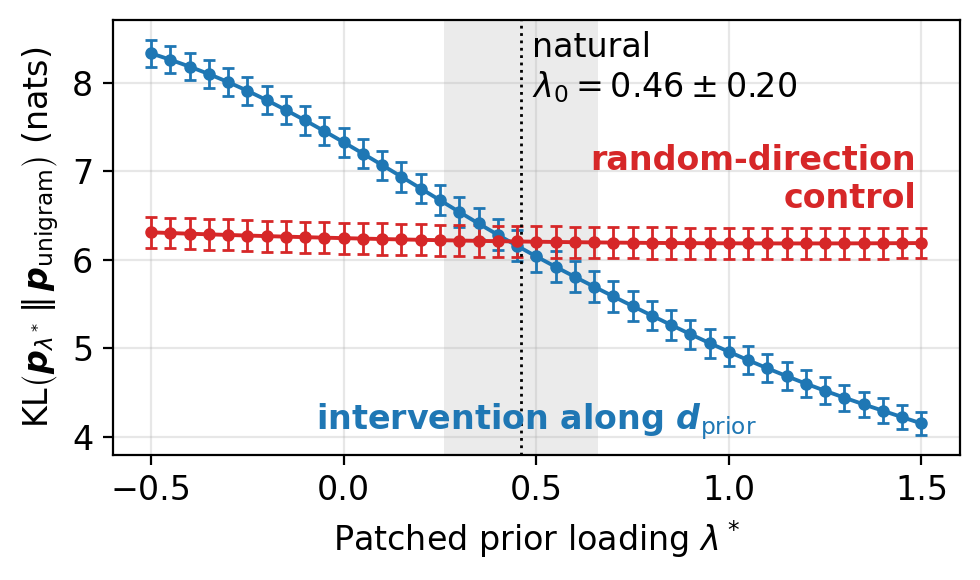

In [10]:
# Figure 7 (main) — KL to the unigram distribution versus the patched prior
# loading lambda*, with the magnitude-matched random-direction control in red.
FS = 12
fig, ax = plt.subplots(figsize=(5, 3), dpi=200)

# Bold colored tags instead of a legend (fig2 style): the control is tagged
# above its endpoint; the treatment tag sits at the bottom center of the plot.
for mat, color in (
    (kl_unigram_prior_dir, "C0"),
    (kl_unigram_random, "C3"),
):
    mean, err = mean_2se(mat)  # 2 SE whiskers
    ax.errorbar(
        lambda_grid, mean, yerr=err/2,
        fmt="-o", markersize=3.5, lw=1.4, color=color,
        elinewidth=1.0, capsize=2.0, capthick=1.0,
    )

control_mean, _ = mean_2se(kl_unigram_random)
ax.annotate(
    "random-direction\ncontrol",
    xy=(lambda_grid[-1], control_mean[-1]),
    xytext=(-2, 10),
    textcoords="offset points",
    color="C3",
    fontsize=FS,
    fontweight="bold",
    ha="right",
    va="bottom",
    annotation_clip=False,
)
ax.annotate(
    "intervention along " + r"$\boldsymbol{d}_{\mathrm{prior}}$",
    xy=(0.5, 0.03), xycoords="axes fraction",
    color="C0",
    fontsize=FS,
    fontweight="bold",
    ha="center",
    va="bottom",
)

# Natural prior loading: mean line with a translucent +/- 1 SD band.
lambda_0_mean = float(lambda_0.mean())
lambda_0_std = float(lambda_0.std(ddof=1))
ax.axvspan(
    lambda_0_mean - lambda_0_std, lambda_0_mean + lambda_0_std,
    color="k", alpha=0.08, linewidth=0,
)
ax.axvline(lambda_0_mean, color="k", lw=1.0, ls=":")
ax.annotate(
    "natural\n" + rf"$\lambda_0={lambda_0_mean:.2f}\pm{lambda_0_std:.2f}$",
    xy=(lambda_0_mean, 1.0), xycoords=("data", "axes fraction"),
    xytext=(4, -4), textcoords="offset points",
    ha="left", va="top", fontsize=FS, color="k",
)

ax.set_xlabel(r"Patched prior loading $\lambda^*$", fontsize=FS)
ax.set_ylabel(
    r"$\mathrm{KL}\left(\boldsymbol{p}_{\lambda^*}\,\|\,\boldsymbol{p}_{\mathrm{unigram}}\right)$ (nats)",
    fontsize=FS,
)
# ax.set_title(
#     f"{model_name.split('/')[1]} — patching "
#     r"$\boldsymbol{y}(\lambda^*)=\boldsymbol{y}+(\lambda^*-\lambda_0)\,\beta^{*}\hat{\boldsymbol{d}}_{\mathrm{prior}}$"
#     f" at position {position}",
#     fontsize=FS,
# )
ax.tick_params(labelsize=FS)
ax.grid(True, alpha=0.3)
fig.tight_layout()

coverage_tag = f"{vocab_coverage:g}".replace(".", "p")
export_dir = Path("plot_export")
export_dir.mkdir(parents=True, exist_ok=True)
export_path = export_dir / (
    f"lambda_intervention_{model_name.split('/')[1]}"
    f"_N{script_num}_coverage{coverage_tag}_pos{position}_narrow.pdf"
)
fig.savefig(export_path, bbox_inches="tight")
print(f"fig saved at {export_path}")
plt.show()

wide sweep: KL(p_lambda || p_unigram) minimized at lambda* = 4.20 (mean KL = 3.3138)


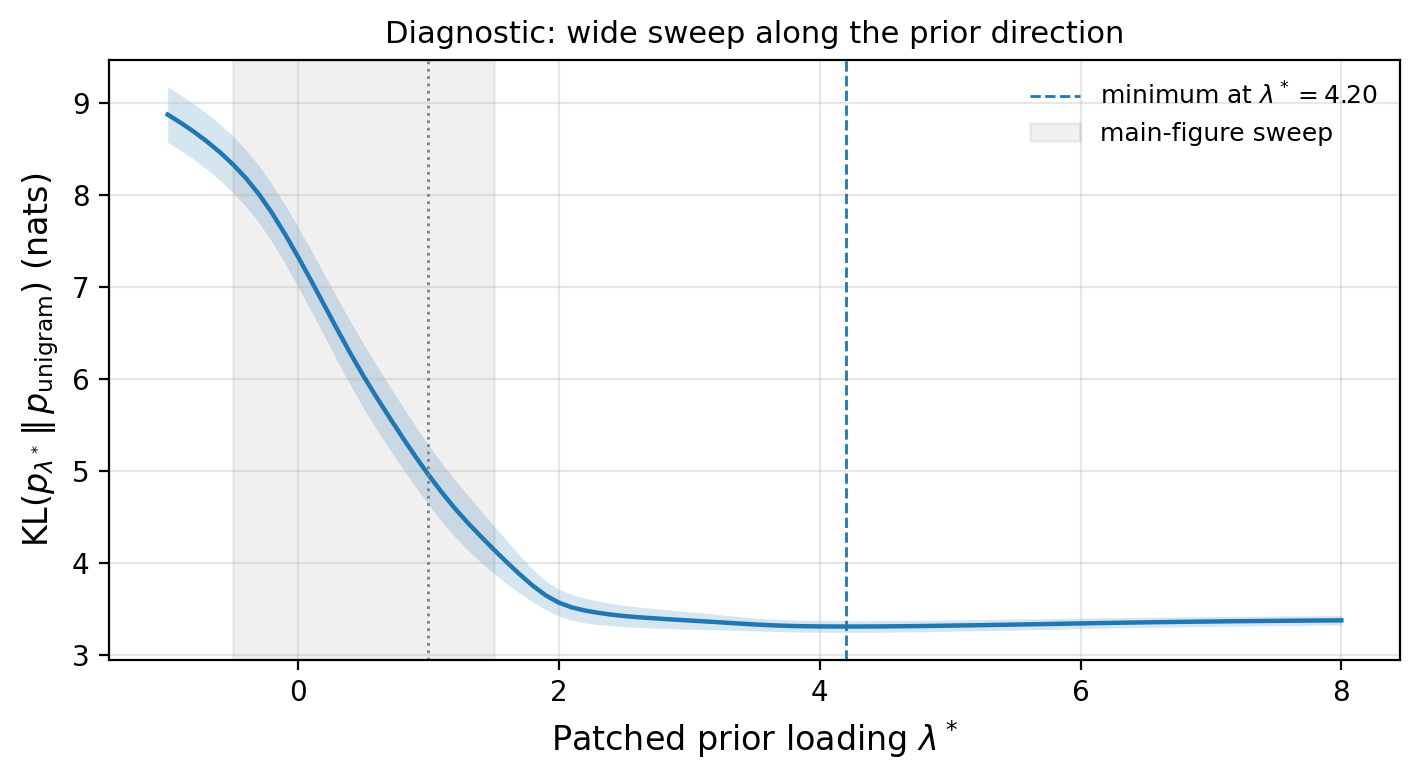

In [ ]:
# Diagnostic: wide sweep to locate the actual KL minimum. Within the paper
# sweep [-0.5, 1.5] the curve is still monotonically decreasing; this shows
# where it turns around and how far above zero the floor sits.
wide_grid = np.linspace(-1.0, 8.0, 91)
wide_kl = np.empty((wide_grid.size, base_logits.shape[0]))
for i, lam in enumerate(wide_grid):
    shift = (lam - lambda_0) * beta_star
    logits = base_logits + shift[:, None] * profile_prior[None, :]
    logits -= logits.max(axis=1, keepdims=True)
    log_p = logits - np.log(np.exp(logits).sum(axis=1, keepdims=True))
    wide_kl[i] = (np.exp(log_p) * (log_p - log_p_unigram[None, :])).sum(axis=1)

wide_mean, wide_err = mean_2se(wide_kl)
wide_min_idx = int(wide_mean.argmin())
print(
    f"wide sweep: KL(p_lambda || p_unigram) minimized at "
    f"lambda* = {wide_grid[wide_min_idx]:.2f} "
    f"(mean KL = {wide_mean[wide_min_idx]:.4f})"
)

fig, ax = plt.subplots(figsize=(7.2, 4.0), dpi=200)
ax.plot(wide_grid, wide_mean, "-", lw=1.6, color="C0")
ax.fill_between(
    wide_grid, wide_mean - wide_err, wide_mean + wide_err,
    color="C0", alpha=0.18, linewidth=0,
)
ax.axvline(1.0, color="gray", lw=1.0, ls=":")
ax.axvline(
    wide_grid[wide_min_idx], color="C0", lw=1.0, ls="--",
    label=rf"minimum at $\lambda^*={wide_grid[wide_min_idx]:.2f}$",
)
ax.axvspan(-0.5, 1.5, color="k", alpha=0.06, label="main-figure sweep")
ax.set_xlabel(r"Patched prior loading $\lambda^*$", fontsize=FS)
ax.set_ylabel(r"$\mathrm{KL}(p_{\lambda^*}\,\|\,p_{\mathrm{unigram}})$ (nats)", fontsize=FS)
ax.set_title("Diagnostic: wide sweep along the prior direction", fontsize=FS - 1)
ax.grid(True, alpha=0.3)
ax.legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()